In [5]:
# General Imports
import sys
from pathlib import Path
import pickle
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# Add project root
project_root = Path.cwd().parents[1]
sys.path.append(str(project_root))

# Internal Imports
from main import tools, model, honeycomb_specific
#from workflows.data_creation.state_factory import get_state

# Data Path
PROCESSED_DATA_PATH = Path("data/processed")
FIGURES_DATA_PATH = Path("data/figures")

# Colors
Cs = tools.visualization.Colors
colors = [Cs.RED, Cs.GREEN, Cs.BLUE]

# Metric conversion
cm = 1/2.54

### Data Loader

In [6]:
def get_processed_data(method, m_ref):
    file_name = f"ZeroPointEntropy_{method}_{m_ref}m"
    file_path = PROCESSED_DATA_PATH / f"{file_name}.pkl"

    with open(file_path, "rb") as f:
        data = pickle.load(f)
    return data

### Plotters

In [7]:
m_size = 9
METHOD_TO_MARKER_STYLE = {
    "monte_carlo": dict(
        marker=".", markersize=m_size, markeredgewidth=0.75, markeredgecolor=Cs.BLACK),
    "tensor_network_contraction": dict(
        marker="+", markersize=m_size+1, markeredgewidth=1, markeredgecolor=Cs.BLACK),
    "exact_enumeration": dict(
        marker="x", markersize=m_size-1, markeredgewidth=1, markeredgecolor=Cs.BLACK)}
MC_FIT_LINE_STYLE = dict(zorder=5, ls="--", lw=1)
TEXT_STYLE = dict(color=Cs.BLACK, fontsize=10)
TEXT_STYLE_LABEL = dict(color=Cs.BLACK, fontsize=8)

METHOD_TO_ZORDER = {
    "exact_enumeration": 2, 
    "tensor_network_contraction": 1, 
    "monte_carlo_HoneycombRectangularUnitCell": 4,
    "monte_carlo_HoneycombUnitCell": 3}
M_REF_TO_ZORDER = {"3":10, "2":20, "1":30}


lattice_nubers = {
    "HoneycombRectangularUnitCell": {
        (3,2): "A1",
        (6,3): "A2",
        (9,4): "A3",
        (12,5): "A4",
        (3,3): "A5",
        (6,4): "A6"},
    "HoneycombUnitCell": {
        (3,3): "B1",
        (6,6): "B2",
        (9,9): "B3",
        (12,12): "B4"}}



def exp_func(N, shift, base):
    return shift * base**N



def plt_monte_carlo(ax:Axes=None):
    methods = ["monte_carlo", "exact_enumeration", "tensor_network_contraction"]
    
    # Init figure
    if ax is None:
        tools.visualization.setup_matplotlib_style()
        fig, ax = plt.subplots(figsize=(3, 4))
        ax_given = False
    else:
        ax_given = True
    
    m_refs = [1, 2, 3]
    start_ind_for_fit = 1
    for i, m_ref in enumerate(m_refs):

        # Go though methods
        for method in methods:

            # Load Data
            data = get_processed_data(method, m_ref)
            Ns, omegas = data["num_of_sites"], data["num_of_states"]
            unit_cell_names = data["additional_info"]["unit_cell_name"]
            L1s, L2s = data["L1s"], data["L2s"]
            # Go though each datapoint N
            for j in range(len(Ns)):
                N, omega = Ns[j], omegas[j]
                unit_cell_name = unit_cell_names[j]
                L1, L2 = L1s[j], L2s[j]

                # Key for zorder of datapoints
                if method == "monte_carlo":
                    key = method+"_"+unit_cell_name
                else:
                    key = method
                zorder = METHOD_TO_ZORDER[key] + M_REF_TO_ZORDER[str(m_ref)]
                
                # Plot datapoints
                ax.plot(
                    N, omega,
                    color=colors[m_ref-1], zorder=zorder, **METHOD_TO_MARKER_STYLE[method])
                
                # Label datapoint with number corresponding to lattice
                if method == "monte_carlo":
                    lattice_number = lattice_nubers[unit_cell_name][(L1, L2)]
                    if N > 20:
                        x_txt = N
                        ha = "center"
                    else:
                        x_txt = N-3
                        ha = "right"
                    if lattice_number[0] == "A":
                        y_txt = omega*1.3
                        va = "bottom"
                    else:
                        y_txt = omega*0.7
                        va = "top"
                    ax.text(
                        x_txt, y_txt, lattice_nubers[unit_cell_name][(L1, L2)],
                        ha=ha, va=va, **TEXT_STYLE_LABEL)
            
            
            if method == "monte_carlo":
                Ns = np.asarray(Ns)
                omegas = np.asarray(omegas)
                idx = np.argsort(Ns)
                Ns = Ns[idx]
                omegas = omegas[idx]
                unique_Ns, inverse_idx = np.unique(Ns, return_inverse=True)

                # Average omegas for each unique N
                avg_omegas = np.zeros_like(unique_Ns, dtype=float)
                for i, N in enumerate(unique_Ns):
                    avg_omegas[i] = omegas[inverse_idx == i].mean()
                Ns = unique_Ns
                omegas = avg_omegas

                # Fit curve
                popt, _ = curve_fit(exp_func, Ns[start_ind_for_fit:], omegas[start_ind_for_fit:])
                shift_fit, alpha_fit = popt
                
                # Plot fitted curve
                Ns_ext = {"3":11, "2":4, "1":7}
                Ns_fit = np.linspace(Ns[start_ind_for_fit]-3, Ns[-1]+Ns_ext[str(m_ref)], num=1000)
                fit = exp_func(Ns_fit, shift_fit, alpha_fit)
                ax.plot(Ns_fit, fit, color=colors[m_ref-1], **MC_FIT_LINE_STYLE)
                
                # Label fitted curve with fit parameter (states per site)
                if m_ref == 3:
                    x_txt, y_txt = Ns_fit[-1]+1, fit[-1]*1.1
                elif m_ref == 2:
                    x_txt, y_txt = Ns_fit[-1]+1, fit[-1]*1.1
                elif m_ref == 1:
                    x_txt, y_txt = Ns_fit[-1]-40, fit[-1]*0.1
                ax.text(
                    x_txt, y_txt, f"$\propto {round(alpha_fit,3)}^N$",
                    ha="left", va="center", **TEXT_STYLE)

    # Legend
    labels = ["MC", "TNC", "EE"]
    legend_handles = [
        Patch(facecolor=colors[2], edgecolor=Cs.BLACK, label=r"$f=1/2$"),
        Patch(facecolor=colors[1], edgecolor=Cs.BLACK, label=r"$f=1/3$"),
        Patch(facecolor=colors[0], edgecolor=Cs.BLACK, label=r"$f=1/6$")]
    for i, (key, style) in enumerate(METHOD_TO_MARKER_STYLE.items()):
        handle = Line2D([0], [0], linestyle='none', color=Cs.GRAY, label=labels[i],**style)
        legend_handles.append(handle)
    ax.legend(handles=legend_handles, loc="upper left", frameon=False)

    # Layout
    ax.set_ylabel(r"number of states $\Omega$")
    ax.set_xlabel(r"number of sites $N\propto L^2$")
    ax.set_yscale("log")
    ax.set_xlim(-10, 300)
    ax.set_ylim(1e1, 1e8)
    ax.tick_params(which='both', direction='in')
    
    if not ax_given:
        fig.tight_layout()
        
    return ax


In [8]:
m_size = 6
MARKER_STYLES = [
    dict(zorder=10, ls="none", marker="x", markersize=m_size),
    dict(zorder=10, ls="none", marker="1", markersize=m_size+2),
    dict(zorder=10, ls="none", marker="+", markersize=m_size+1)]
FIT_LINE_STYLE = dict(zorder=5, ls="-", lw=1)
FIT_EXTRAPOLATED_LINE_STYLE = dict(zorder=6, ls="--", lw=1)
CALLOUT_LINE_STYLE = dict(zorder=0, color=Cs.GRAY, linestyle='-', linewidth=0.75)
TEXT_STYLE = dict(color=Cs.BLACK, fontsize=10)


def lin_func(inv_ls, alpha, k):
    return alpha+inv_ls*k



def plt_power_method(ax:Axes=None):
    method = "power_method"
    
    # Init figure
    if ax is None:
        tools.visualization.setup_matplotlib_style()
        fig, ax = plt.subplots(figsize=(6, 4))
        ax_given = False
    else:
        ax_given = True

    hline_ls = [0.07, 0.07, 0.07]
    m_refs = [3, 2, 1]
    start_ind_for_fit = 1
    for i, m_ref in enumerate(m_refs):

        # Load Data
        data = get_processed_data(method, m_ref)
        ls = np.array(data["ls"])
        alphas = data["alphas"]
        
        # Invert transfer matrix length
        inv_ls = 1/ls

        # Plot data
        ax.plot(inv_ls, alphas, color=colors[m_ref-1], **MARKER_STYLES[0])

        # Fit line
        popt, _ = curve_fit(lin_func, inv_ls[start_ind_for_fit:], alphas[start_ind_for_fit:])
        alpha_0, k = popt

        # Plot fitted line and x=0 corssing
        inv_ls_fit = np.linspace(0, inv_ls[-1], 2)
        ax.plot(inv_ls_fit, lin_func(inv_ls_fit, alpha_0, k), color=colors[m_ref-1], **FIT_EXTRAPOLATED_LINE_STYLE)
        inv_ls_fit = np.linspace(inv_ls[-1], inv_ls[start_ind_for_fit], 2)
        ax.plot(inv_ls_fit, lin_func(inv_ls_fit, alpha_0, k), color=colors[m_ref-1], **FIT_LINE_STYLE)
        inv_ls_fit = np.linspace(inv_ls[start_ind_for_fit], 0.6, 2)
        ax.plot(inv_ls_fit, lin_func(inv_ls_fit, alpha_0, k), color=colors[m_ref-1], **FIT_EXTRAPOLATED_LINE_STYLE)
        ax.plot([0, hline_ls[i]+0.085], [alpha_0, alpha_0], **CALLOUT_LINE_STYLE)
        ax.text(
            hline_ls[i], alpha_0, s=(r"$"+str(round(alpha_0, 3))+r"$"), 
            ha="left", va="bottom", **TEXT_STYLE)
    
    # Legend
    label = r"dominant EV $\alpha$"
    legend_handles = []
    legend_handles.append(
        Line2D([0], [0], linestyle='none', color=Cs.GRAY, label=label, **MARKER_STYLES[0]))
    ax.legend(handles=legend_handles, loc="upper left", frameon=False)

    # Layout
    ax.set_ylabel(r"states per site $\alpha$")
    ax.set_xlabel(r"inverse transfer-matrix length $1/l$")
    ax.set_xlim([0, 0.6])
    ax.set_ylim([1.0, 1.5])
    ax.tick_params(which='both', direction='in')
    
    if not ax_given:
        fig.tight_layout()
        
    return ax



def plt_pauling_like_estimate(ax:Axes=None):
    method = "pauling_like_estimate"
    
    # Init figure
    if ax is None:
        tools.visualization.setup_matplotlib_style()
        fig, ax = plt.subplots(figsize=(3, 4))
        ax_given = False
    else:
        ax_given = True

    x_offset = [0.17, 0.17, 0.17]
    m_refs = [3, 2, 1]
    start_ind_for_fit = 0
    for i, m_ref in enumerate(m_refs):

        # Load Data
        data = get_processed_data(method, m_ref)
        gap_tile_ratios = np.array(data["gap_tile_ratios"])
        alpha_maxs = np.array(data["alpha_maxs"])
        Ps = np.array(data["Ps"])
        print(f"alpha_max: {round(alpha_maxs[-1],3)}")

        # Compute alpha
        alpha = Ps*alpha_maxs

        # Plot data
        ax.plot(gap_tile_ratios, alpha_maxs, color=colors[m_ref-1], **MARKER_STYLES[1])
        ax.plot(gap_tile_ratios, alpha,  color=colors[m_ref-1], **MARKER_STYLES[0])
        ax.plot(gap_tile_ratios, Ps, color=colors[m_ref-1], **MARKER_STYLES[2])

        # Highlight best guess
        x_best_guess = gap_tile_ratios[-1]
        y_best_guess = alpha[-1]
        ax.plot(
            [x_best_guess-x_offset[i], x_best_guess], [y_best_guess, y_best_guess], 
            **CALLOUT_LINE_STYLE)
        ax.text(
            x_best_guess+0.005-x_offset[i], y_best_guess, 
            s=(r"$"+str(round(y_best_guess, 3))+r"$"),
            ha="left", va="bottom", **TEXT_STYLE)
        
        # Fit lines
        if m_ref == 3:
            for val in [alpha_maxs, Ps]:
                popt, _ = curve_fit(lin_func, gap_tile_ratios[start_ind_for_fit:], val[start_ind_for_fit:])
                x = np.linspace(0, gap_tile_ratios[-1], 2)
                ax.plot(
                    x, lin_func(x, popt[0], popt[1]), color=colors[m_ref-1], **FIT_EXTRAPOLATED_LINE_STYLE)
                x = np.linspace(gap_tile_ratios[-1], gap_tile_ratios[start_ind_for_fit], 2)
                ax.plot(
                    x, lin_func(x, popt[0], popt[1]), color=colors[m_ref-1], **FIT_LINE_STYLE)
                x = np.linspace(gap_tile_ratios[start_ind_for_fit], 0.8, 2)
                ax.plot(
                    x, lin_func(x, popt[0], popt[1]), color=colors[m_ref-1], **FIT_EXTRAPOLATED_LINE_STYLE)

    # Legend
    labels = [r"$\alpha_\mathrm{max}$", r"$\alpha=P\,\alpha_\mathrm{max}$", r"$P$"]
    legend_handles = []
    for i, MARKER_STYLE in enumerate([MARKER_STYLES[1], MARKER_STYLES[0], MARKER_STYLES[2]]):
        legend_handles.append(
            Line2D([0], [0], linestyle='none', color=Cs.GRAY, label=labels[i], **MARKER_STYLE))
    ax.legend(handles=legend_handles, loc="upper left", frameon=False)

    # Layout
    ax.set_ylabel(r"compatibility $P$ / states per site $\alpha$")
    ax.set_xlabel(r"boundary-to-area ratio $N_\mathrm{gap}/N_\mathrm{area}$")
    ax.set_xlim([0, 0.8])
    ax.set_ylim([0.6, 1.8])
    ax.tick_params(which='both', direction='in')

    if not ax_given:
        fig.tight_layout()

    return ax


### Plotting

/tmp/ipykernel_1602300/4049228156.py:38: RuntimeWarning: overflow encountered in power
  return shift * base**N


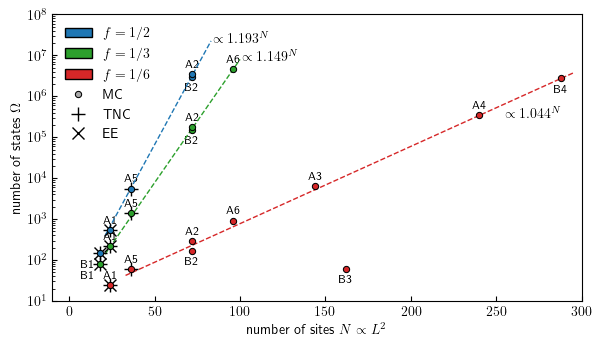

In [5]:
tools.visualization.setup_matplotlib_style()
fig, ax = plt.subplots(figsize=(15*cm, 8.5*cm), constrained_layout=True)
ax = plt_monte_carlo(ax)

file_name = "ZPE_MC"
file_path = FIGURES_DATA_PATH / f"{file_name}"
fig.savefig(f"{file_path}.pdf")
plt.show()

alpha_max: 1.435
alpha_max: 1.384
alpha_max: 1.237


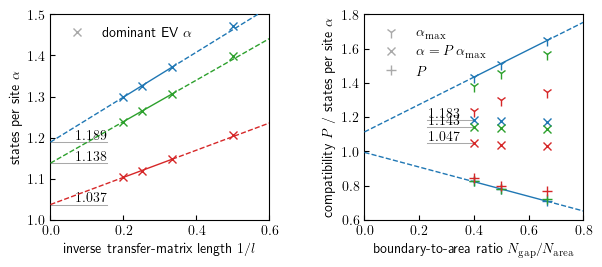

In [9]:
tools.visualization.setup_matplotlib_style()
fig, ax = plt.subplots(1, 2, figsize=(15*cm, 6.5*cm), width_ratios=[0.5, 0.5], constrained_layout=True)
ax[0] = plt_power_method(ax[0])
ax[1] = plt_pauling_like_estimate(ax[1])
fig.set_constrained_layout_pads(wspace=0.15)

file_name = "ZPE_TM_PE"
file_path = FIGURES_DATA_PATH / f"{file_name}"
fig.savefig(f"{file_path}.pdf")

### Lattice Geometries

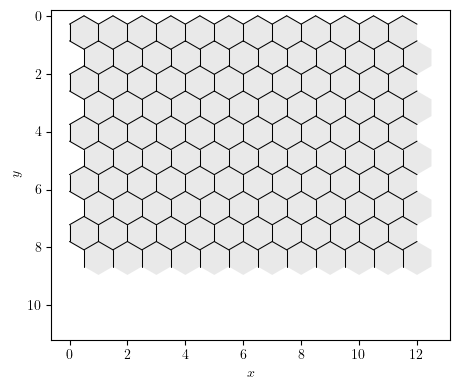

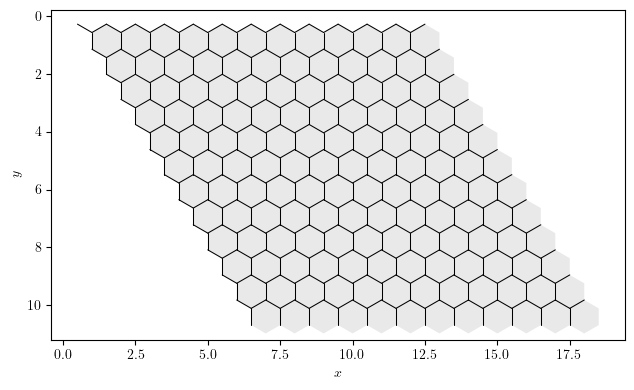

In [7]:
unit_cells = [model.unit_cell.HoneycombRectangularUnitCell(), model.unit_cell.HoneycombUnitCell()]
L1s, L2s = [12, 12], [5, 12]
for i, unit_cell in enumerate(unit_cells):
    tools.visualization.setup_matplotlib_style()
    fig, ax = plt.subplots(figsize=(10, 4))
    lattice = model.lattice.LatticeFromUnitCell(L1s[i], L2s[i], unit_cell)
    honeycomb_specific.visualization.plt_HC_lattice(lattice, show_sites=False, ylim=[-0.2,11.2], ax=ax)
    file_name = f"Lattice_for_ZPE_{i}"
    file_path = FIGURES_DATA_PATH / f"{file_name}"
    fig.savefig(f"{file_path}.pdf")